# AI Programming Foundations — Data Workflow

**Name:** Sijuade Oguntayo

**Dataset chosen:** Road Traffic Accident Severity (RTA) Dataset — 12,316 road traffic accident records with 32 columns covering driver, vehicle, road, and environmental conditions.

**Project description:** This notebook ingests the Road Traffic Accident Severity dataset, cleans missing and inconsistently formatted fields, and explores how accident severity relates to the time of day and weather conditions. It then visualizes these patterns using Matplotlib and Seaborn before closing with a written summary of the key findings and limitations. This is the first of seven capstone projects in a broader ADAS and road-scene perception pipeline.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("RTA Dataset.csv")
df.head()

,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,...,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
0,17:02:00,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,Above 10yr,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Moving Backward,Slight Injury
1,17:02:00,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,5-10yrs,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury
2,17:02:00,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,NaN,...,Going straight,Driver or rider,Male,31-50,3,Driver,NaN,Not a Pedestrian,Changing lane to the left,Serious Injury
3,1:06:00,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Public (> 45 seats),Governmental,NaN,...,Going straight,Pedestrian,Female,18-30,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Slight Injury
4,1:06:00,Sunday,18-30,Male,Junior high school,Employee,2-5yr,NaN,Owner,5-10yrs,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury


In [2]:
df.describe()

,Number_of_vehicles_involved,Number_of_casualties
count,12316.000000,12316.000000
mean,2.040679,1.548149
std,0.688790,1.007179
min,1.000000,1.000000
25%,2.000000,1.000000
50%,2.000000,1.000000
75%,2.000000,2.000000
max,7.000000,8.000000


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12316 entries, 0 to 12315
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Time                         12316 non-null  str  
 1   Day_of_week                  12316 non-null  str  
 2   Age_band_of_driver           12316 non-null  str  
 3   Sex_of_driver                12316 non-null  str  
 4   Educational_level            11575 non-null  str  
 5   Vehicle_driver_relation      11737 non-null  str  
 6   Driving_experience           11487 non-null  str  
 7   Type_of_vehicle              11366 non-null  str  
 8   Owner_of_vehicle             11834 non-null  str  
 9   Service_year_of_vehicle      8388 non-null   str  
 10  Defect_of_vehicle            7889 non-null   str  
 11  Area_accident_occured        12077 non-null  str  
 12  Lanes_or_Medians             11931 non-null  str  
 13  Road_allignment              12174 non-null  str  
 14  T

In [4]:
df.shape

(12316, 32)

## Data Cleaning

In [5]:
def fill_missing_categorical(df, fill_value="Unknown"):
    """
    Fill missing values in object/string (categorical) columns with a placeholder label.

    Parameters
    ----------
    df : pandas.DataFrame
        The dataframe to clean.
    fill_value : str, optional
        The label used to replace missing values (default "Unknown").

    Returns
    -------
    pandas.DataFrame
        A copy of df with missing values in categorical columns filled.
    """
    df_clean = df.copy()
    categorical_cols = df_clean.select_dtypes(include=["object", "str"]).columns
    df_clean[categorical_cols] = df_clean[categorical_cols].fillna(fill_value)
    return df_clean


def extract_hour_from_time(df, time_col="Time", new_col="Hour_of_day"):
    """
    Parse a HH:MM:SS time string column and extract the hour of day as an integer.

    Parameters
    ----------
    df : pandas.DataFrame
        The dataframe containing the time column.
    time_col : str, optional
        Name of the column holding time strings (default "Time").
    new_col : str, optional
        Name of the new integer hour-of-day column to create (default "Hour_of_day").

    Returns
    -------
    pandas.DataFrame
        A copy of df with the new hour-of-day column added.
    """
    df_clean = df.copy()
    df_clean[new_col] = pd.to_datetime(df_clean[time_col], format="%H:%M:%S").dt.hour
    return df_clean

In [6]:
df_clean = fill_missing_categorical(df)
df_clean = extract_hour_from_time(df_clean)

print("Remaining missing values:", df_clean.isnull().sum().sum())
df_clean[["Time", "Hour_of_day"]].head()

Remaining missing values: 0


,Time,Hour_of_day
0,17:02:00,17
1,17:02:00,17
2,17:02:00,17
3,1:06:00,1
4,1:06:00,1


## Exploratory Data Analysis

In [7]:
def summarize_by_severity(df, group_col="Accident_severity"):
    """
    Compute summary statistics for numeric columns grouped by accident severity,
    plus the overall correlation between numeric features.

    Parameters
    ----------
    df : pandas.DataFrame
        The cleaned dataframe.
    group_col : str, optional
        The categorical column to group by (default "Accident_severity").

    Returns
    -------
    tuple(pandas.DataFrame, pandas.DataFrame)
        A (grouped_summary, correlation_matrix) pair.
    """
    numeric_cols = df.select_dtypes(include=np.number).columns
    grouped_summary = df.groupby(group_col)[numeric_cols].mean()
    correlation_matrix = df[numeric_cols].corr()
    return grouped_summary, correlation_matrix

severity_summary, corr_matrix = summarize_by_severity(df_clean)
print(severity_summary)
print()
print(corr_matrix)

                   Number_of_vehicles_involved  Number_of_casualties  \
Accident_severity                                                      
Fatal injury                          1.797468              2.341772   
Serious Injury                        1.895009              1.535284   
Slight Injury                         2.068747              1.538262   

                   Hour_of_day  
Accident_severity               
Fatal injury         14.797468  
Serious Injury       13.931153  
Slight Injury        13.805281  

                             Number_of_vehicles_involved  \
Number_of_vehicles_involved                     1.000000   
Number_of_casualties                            0.213427   
Hour_of_day                                     0.023095   

                             Number_of_casualties  Hour_of_day  
Number_of_vehicles_involved              0.213427     0.023095  
Number_of_casualties                     1.000000     0.051761  
Hour_of_day                          

## Visualizations

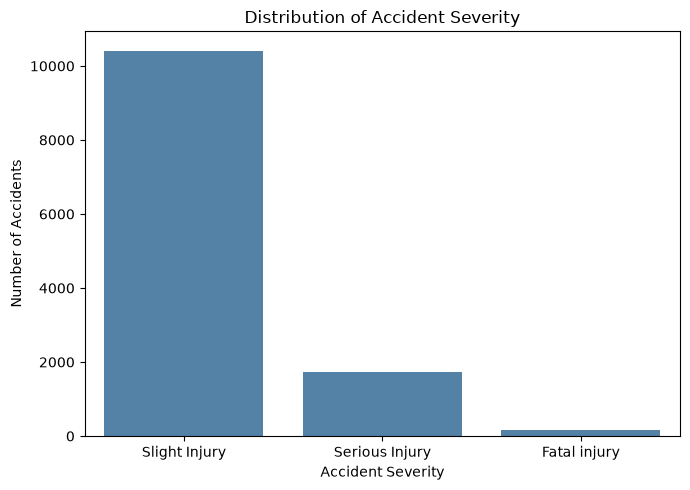

In [8]:
plt.figure(figsize=(7, 5))
sns.countplot(
    data=df_clean,
    x="Accident_severity",
    order=df_clean["Accident_severity"].value_counts().index,
    color="steelblue",
)
plt.title("Distribution of Accident Severity")
plt.xlabel("Accident Severity")
plt.ylabel("Number of Accidents")
plt.tight_layout()
plt.show()

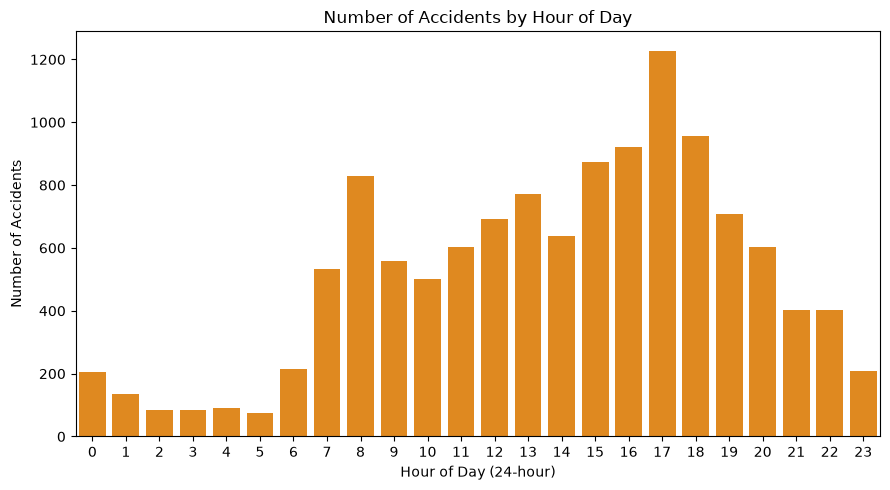

In [9]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df_clean, x="Hour_of_day", color="darkorange")
plt.title("Number of Accidents by Hour of Day")
plt.xlabel("Hour of Day (24-hour)")
plt.ylabel("Number of Accidents")
plt.tight_layout()
plt.show()

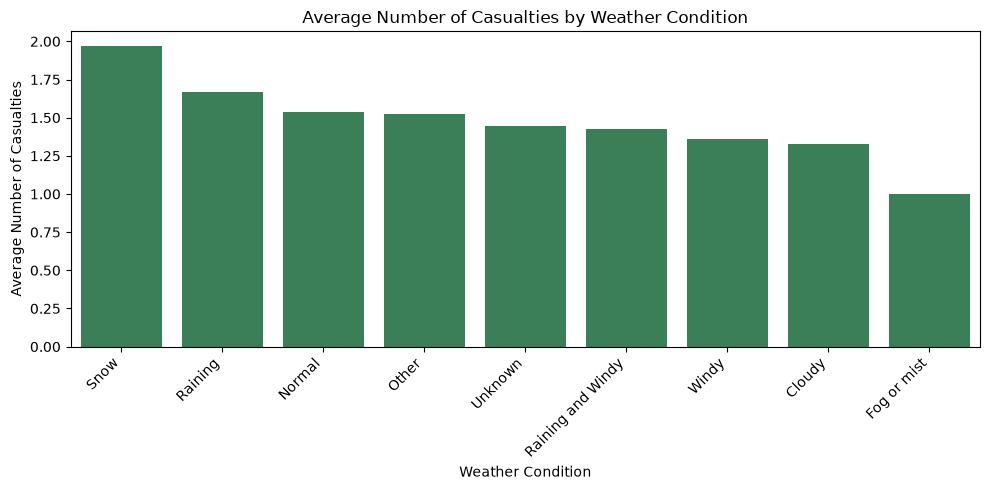

In [10]:
casualties_by_weather = (
    df_clean.groupby("Weather_conditions")["Number_of_casualties"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
sns.barplot(x=casualties_by_weather.index, y=casualties_by_weather.values, color="seagreen")
plt.title("Average Number of Casualties by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Average Number of Casualties")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Summary

This dataset of 12,316 road traffic accident records revealed several notable patterns during cleaning and exploration. Most accidents (over 80%) result in slight injuries, with fatal injuries being comparatively rare (around 1.3%), showing that the severity classes are highly imbalanced, an important consideration for any future predictive modeling. Accident frequency peaks sharply in the late afternoon (around 17:00), likely reflecting rush-hour traffic, while the early morning hours see far fewer accidents. Average casualty counts vary only modestly across weather conditions, with rarer conditions like "Windy" and "Snow" showing somewhat higher averages despite very few recorded observations. Several columns (e.g., `Defect_of_vehicle`, `Service_year_of_vehicle`, `Work_of_casuality`) had substantial missing data, which was filled with an explicit "Unknown" placeholder rather than dropped so the row count was preserved, though this introduces ambiguity between true missingness and "not applicable". Overall, the dataset looks well-suited to future classification work predicting accident severity from road, vehicle, and environmental conditions, but the class imbalance and uneven missingness across columns are important caveats for any model built on it.